In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## win-rate

**Figure 4: Human preference evaluation, comparing LIMA to 5 different baselines across 300 test prompts.** LIMA's response is preferred over Alpaca 65B and DaVinci003 more often than theirs, and even against GPT-4 it is equal or better in 43% of prompts (18% wins, 25% ties).

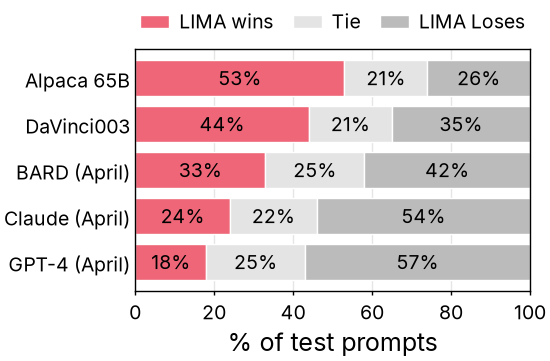

In [2]:
with open("../data/win-rate.json") as f:
    data = json.load(f)

opponents = data["opponents"]
outcome_colors = {"LIMA wins": colors["ours"], "Tie": lighten(colors["neutral"]), "LIMA Loses": colors["neutral"]}

fig, ax = plt.subplots(figsize=(2.75, 2))
y = np.arange(len(opponents))
left = np.zeros(len(opponents))
for outcome in data["categories"]:
    shares = np.array(data[outcome])
    bars = ax.barh(y, shares, left=left, color=outcome_colors[outcome], edgecolor="white", linewidth=0.5, label=outcome)
    ax.bar_label(bars, fmt="%d%%", label_type="center")
    left += shares
ax.set_yticks(y, labels=opponents)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set_xlabel("% of test prompts")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), ncol=3, frameon=False, borderaxespad=0.5)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/win-rate.pdf")
fig.savefig("../outputs/win-rate.png")
plt.show()